# SubPOP

Subpopulation-level opinion distributions from Suh et al. (2025), [jjssuh/subpop](https://huggingface.co/datasets/jjssuh/subpop) (gated, CC BY-NC-SA 4.0).

- `subpop_train.jsonl`: 3,229 questions from Pew American Trends Panel
- `subpop_eval.jsonl`: 133 questions from GSS 2022

One row = one question x one subpopulation (22 groups over 8 attributes), with that group's weighted response distribution.

In [1]:
import pandas as pd
from huggingface_hub import hf_hub_download

REPO = "jjssuh/subpop"
# needs a token with access to the gated repo: HF_TOKEN env var or `hf auth login`
paths = {split: hf_hub_download(REPO, f"subpop_{split}.jsonl", repo_type="dataset") for split in ("train", "eval")}

train = pd.read_json(paths["train"], lines=True)
eval_ = pd.read_json(paths["eval"], lines=True)
print(train.shape, eval_.shape)
train.head()

(71026, 8) (2926, 8)


,qkey,attribute,group,question,options,ordinal,responses,refusal_rate
0,KNOWFAUCI_W68,CREGION,Northeast,Do you happen to know who Anthony Fauci is?,"[Trumps personal doctor, The head of coronavir...","[1.0, 1.0, 1.0, 1.0, 1.0]","[0.004376340386448001, 0.036087142411417, 0.77...",0.001000
1,KNOWFAUCI_W68,CREGION,South,Do you happen to know who Anthony Fauci is?,"[Trumps personal doctor, The head of coronavir...","[1.0, 1.0, 1.0, 1.0, 1.0]","[0.007728461344962001, 0.05664318660985, 0.632...",0.009147
2,KNOWFAUCI_W68,EDUCATION,College graduate/some postgrad,Do you happen to know who Anthony Fauci is?,"[Trumps personal doctor, The head of coronavir...","[1.0, 1.0, 1.0, 1.0, 1.0]","[0.0058410208731970005, 0.031261775340393004, ...",0.003430
3,KNOWFAUCI_W68,EDUCATION,Less than high school,Do you happen to know who Anthony Fauci is?,"[Trumps personal doctor, The head of coronavir...","[1.0, 1.0, 1.0, 1.0, 1.0]","[0.004764826127695, 0.085584323965461, 0.38090...",0.000350
4,KNOWFAUCI_W68,SEX,Male,Do you happen to know who Anthony Fauci is?,"[Trumps personal doctor, The head of coronavir...","[1.0, 1.0, 1.0, 1.0, 1.0]","[0.005799529028381, 0.042083105317945006, 0.76...",0.004785


In [2]:
train.groupby(['attribute', 'group'])['responses'].count()

attribute    group                         
CREGION      Northeast                         3229
             South                             3229
EDUCATION    College graduate/some postgrad    3229
             Less than high school             3229
INCOME       $100,000 or more                  3229
             Less than $30,000                 3229
POLIDEOLOGY  Conservative                      3229
             Liberal                           3229
             Moderate                          3229
POLPARTY     Democrat                          3229
             Republican                        3229
RACE         Asian                             3229
             Black                             3229
             Hispanic                          3229
             White                             3229
RELIG        Atheist                           3225
             Hindu                             3227
             Jewish                            3227
             Muslim 

Questions, subpopulations, and rows per split:

In [4]:
train.groupby(['attribute', 'group'])['qkey'].count()

attribute    group                         
CREGION      Northeast                         3229
             South                             3229
EDUCATION    College graduate/some postgrad    3229
             Less than high school             3229
INCOME       $100,000 or more                  3229
             Less than $30,000                 3229
POLIDEOLOGY  Conservative                      3229
             Liberal                           3229
             Moderate                          3229
POLPARTY     Democrat                          3229
             Republican                        3229
RACE         Asian                             3229
             Black                             3229
             Hispanic                          3229
             White                             3229
RELIG        Atheist                           3225
             Hindu                             3227
             Jewish                            3227
             Muslim 

In [24]:
train['options'].value_counts().iloc[:50]

options
[Very important, Somewhat important, Not too important, Not at all important, Refused]                                                                                                                              2794
[Yes, No, Refused]                                                                                                                                                                                                  2508
[Very well, Somewhat well, Not too well, Not at all well, Refused]                                                                                                                                                  1914
[A lot, A little, Nothing at all, Refused]                                                                                                                                                                          1232
[A very big problem, A moderately big problem, A small problem, Not a problem at all, Refused]                              

Check the shape of the distributions. In the first rows, `options` ends with `"Refused"` but `responses` has one entry fewer
(refusals are reported separately in `refusal_rate`). This cell checks that this holds everywhere and that each distribution sums to 1.

In [8]:
for name, df in [("train", train), ("eval", eval_)]:
    n_opt, n_resp = df.options.str.len(), df.responses.str.len()
    print(name,
          "| last option 'Refused':", (df.options.str[-1] == "Refused").mean().round(3),
          "| len(responses) == len(options) - 1:", (n_resp == n_opt - 1).mean().round(3),
          "| sums to 1:", df.responses.map(lambda r: abs(sum(r) - 1) < 1e-6).mean().round(3))

train | last option 'Refused': 0.994 | len(responses) == len(options) - 1: 1.0 | sums to 1: 1.0
eval | last option 'Refused': 1.0 | len(responses) == len(options) - 1: 1.0 | sums to 1: 1.0


## Released Kev vs our ISSP fine-tuned Kev on SubPOP

Each SubPOP row (eval split: 133 GSS 2022 questions × 22 subpopulations) becomes one model input:
- **persona** = `Country: United States` + the row's one attribute (e.g. `Political party: Republican`). Only Sex and Education were persona fields in our training; the other six attributes are new to the fine-tuned model.
- **question** = SubPOP's question with its answer options as a `choice` question, in SubPOP's order (its `ordinal` field is unreliable; Kev shows `score` and `choice` options identically, so the input is the same). `Refused` is left out.
- **target** = the subpopulation's response distribution.

Both models give **raw distributions** (temperature 1.0), as in training, and are scored with the same KL / JS divergence code as `train.py`.

In [24]:
import sys
import torch
import models            # the model layer: models.load reads any saved model
import train as trainer   # same prediction and metric code as training (`train` is the SubPOP train split here)

ATTRIBUTE = {"CREGION": "Region", "EDUCATION": "Education", "INCOME": "Income", "POLIDEOLOGY": "Political ideology",
             "POLPARTY": "Political party", "RACE": "Race", "RELIG": "Religion", "SEX": "Sex"}

def to_record(row):
    """One SubPOP row in the record format trainer.predict reads: persona fields + one `choice` question."""
    options = row.options[:len(row.responses)]          # drop "Refused": it has no response share
    return {"persona": {"Country": "United States", ATTRIBUTE[row.attribute]: row.group},
            "questions": {row.qkey: {"type": "choice", "instructions": row.question,
                                     "criteria": {option: None for option in options},
                                     "target": dict(zip(options, row.responses))}}}

records = [to_record(row) for row in eval_.itertuples()]
len(records)

2926

In [25]:
print(eval_['question'].iloc[0])

We are faced with many problems in this country, none of which can be solved easily or inexpensively. I'm going to name some of these problems, and for each one I'd like you to tell me whether you think we're spending too much money on it, too little money, or about the right amount: Space exploration program.


In [26]:
records[0]

{'persona': {'Country': 'United States', 'Region': 'Northeast'},
 'questions': {'natspac': {'type': 'choice',
   'instructions': "We are faced with many problems in this country, none of which can be solved easily or inexpensively. I'm going to name some of these problems, and for each one I'd like you to tell me whether you think we're spending too much money on it, too little money, or about the right amount: Space exploration program.",
   'criteria': {'Too little': None, 'About right': None, 'Too much': None},
   'target': {'Too little': 0.307562598107165,
    'About right': 0.41150426949738,
    'Too much': 0.28093313239545503}}}}

In [27]:
MODELS = {"released Kev": "jaredpalmer/kev-0.8b",
          "fine-tuned on ISSP": "runs/issp-0.8b-v3/best"}
autocast = torch.autocast("cuda", dtype=torch.bfloat16)

# one row per SubPOP row and model: how far the predicted distribution is from the subpopulation's answers
scores = []
for name, run in MODELS.items():
    model = models.load(run, "cuda")   # raw distribution: no temperature
    predictions = trainer.with_probs(trainer.predict(model, records, 16, autocast))
    scores.append(pd.DataFrame({
        "model": name, "attribute": eval_.attribute.values, "group": eval_.group.values, "qkey": eval_.qkey.values,
        "kl": [trainer.kl_divergence(p["target"], p["probs"]) for p in predictions],
        "js": [trainer.js_divergence(p["target"], p["probs"]) for p in predictions],
        "observed": [p["target"].numpy() for p in predictions],      # the subpopulation's answer shares
        "predicted": [p["probs"].numpy() for p in predictions]}))   # the model's answer shares
    del model
    torch.cuda.empty_cache()
scores = pd.concat(scores, ignore_index=True)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

### Per profile: mean KL and JS divergence over the 133 questions (lower is better)

`improved` = share of questions where the fine-tuned model's KL is lower than the released model's.

In [28]:
per_profile = scores.pivot_table(index=["attribute", "group"], columns="model", values=["kl", "js"], aggfunc="mean")
kl = scores.pivot_table(index=["attribute", "group", "qkey"], columns="model", values="kl")
improved = kl["fine-tuned on ISSP"] < kl["released Kev"]
per_profile["improved"] = improved.groupby(["attribute", "group"]).mean()

# last row: the same measures over all profiles together
overall = scores.groupby("model")[["kl", "js"]].mean()
per_profile.loc[("all", "all profiles"), :] = [overall.loc[model, metric] for metric, model in per_profile.columns[:-1]] \
                                             + [improved.mean()]
per_profile.round(3)

js               \
model                                      fine-tuned on ISSP released Kev   
attribute   group                                                            
CREGION     Northeast                                   0.092        0.149   
            South                                       0.082        0.154   
EDUCATION   College graduate/some postgrad              0.091        0.137   
            Less than high school                       0.084        0.159   
INCOME      $100,000 or more                            0.101        0.141   
            Less than $30,000                           0.084        0.142   
POLIDEOLOGY Conservative                                0.088        0.170   
            Liberal                                     0.107        0.151   
            Moderate                                    0.091        0.162   
POLPARTY    Democrat                                    0.110        0.169   
            Republican                                  0.098        0.183   
RACE        Asian                                       0.102        0.139   
            Black                                       0.097        0.160   
            Hispanic                                    0.099        0.163   
            White                                       0.088        0.143   
RELIG       Atheist                                     0.105        0.151   
            Hindu                                       0.151        0.204   
            Jewish                                      0.142        0.193   
            Muslim                                      0.167        0.220   
            Protestant                                  0.084        0.162   
SEX         Female                                      0.092        0.146   
            Male                                        0.084        0.142   
all         all profiles                                0.102        0.161   

                                                           kl               \
model                                      fine-tuned on ISSP released Kev   
attribute   group                                                            
CREGION     Northeast                                   0.353        0.698   
            South                                       0.315        0.750   
EDUCATION   College graduate/some postgrad              0.348        0.638   
            Less than high school                       0.321        0.790   
INCOME      $100,000 or more                            0.385        0.636   
            Less than $30,000                           0.321        0.673   
POLIDEOLOGY Conservative                                0.339        0.835   
            Liberal                                     0.412        0.699   
            Moderate                                    0.355        0.791   
POLPARTY    Democrat                                    0.420        0.797   
            Republican                                  0.379        0.899   
RACE        Asian                                       0.383        0.615   
            Black                                       0.369        0.749   
            Hispanic                                    0.375        0.759   
            White                                       0.337        0.677   
RELIG       Atheist                                     0.409        0.725   
            Hindu                                       0.559        0.899   
            Jewish                                      0.539        0.893   
            Muslim                                      0.613        1.002   
            Protestant                                  0.324        0.804   
SEX         Female                                      0.354        0.703   
            Male                                        0.319        0.682   
all         all profiles                                0.388        0.760   

 

### Figures

**Per profile:** each row is one subpopulation; the line runs from the released model (gray) to the fine-tuned model (blue). Further left is better. SEX and EDUCATION were persona fields in training; the other attributes are new.

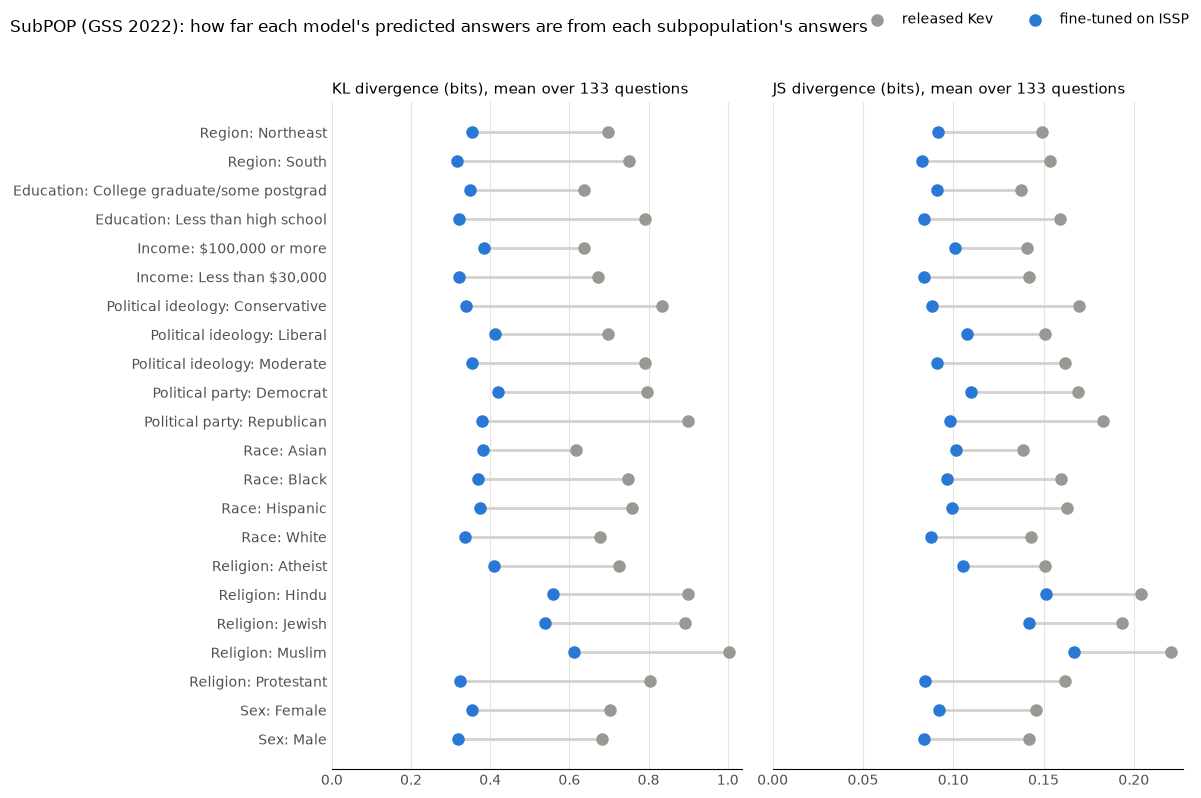

In [29]:
import matplotlib.pyplot as plt

RELEASED, FINE_TUNED = "#9a9893", "#2a78d6"   # baseline in gray, our model in the accent blue
MUTED, LINE = "#52514e", "#d4d2cc"

def tidy(ax):
    """Recessive axes: no box, light vertical grid behind the marks."""
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", color="#e6e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)

profiles = per_profile.drop(index=("all", "all profiles"))
labels = [f"{ATTRIBUTE[attribute]}: {group}" for attribute, group in profiles.index]
y = list(range(len(labels)))[::-1]                     # first profile at the top

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
for ax, metric, title in zip(axes, ["kl", "js"], ["KL divergence (bits)", "JS divergence (bits)"]):
    before, after = profiles[(metric, "released Kev")], profiles[(metric, "fine-tuned on ISSP")]
    ax.hlines(y, after, before, color=LINE, linewidth=2, zorder=1)
    ax.scatter(before, y, s=64, color=RELEASED, label="released Kev", zorder=2)
    ax.scatter(after, y, s=64, color=FINE_TUNED, label="fine-tuned on ISSP", zorder=3)
    ax.set_xlim(left=0)
    ax.set_title(f"{title}, mean over 133 questions", loc="left", fontsize=11)
    tidy(ax)
axes[0].set_yticks(y, labels)
fig.suptitle("SubPOP (GSS 2022): how far each model's predicted answers are from each subpopulation's answers",
             x=0.01, ha="left", fontsize=12)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)   # above the panels
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Per row:** each dot is one subpopulation × question (2,926 in all). Dots below the dashed line are rows where the fine-tuned model is closer to the observed answers than the released model.

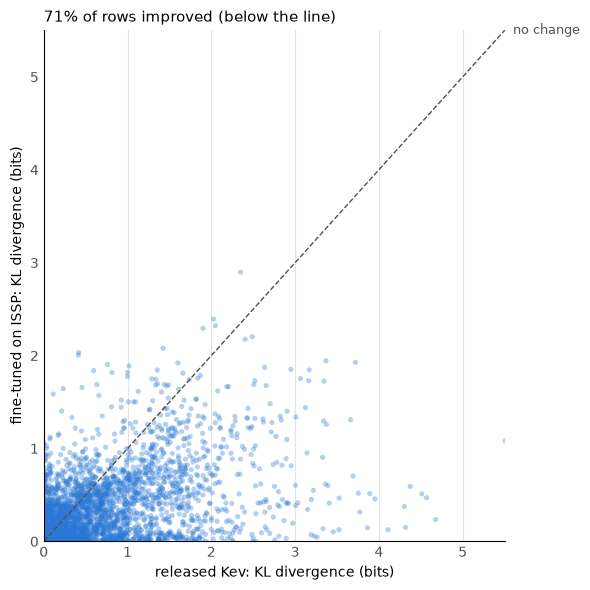

In [30]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(kl["released Kev"], kl["fine-tuned on ISSP"], s=14, alpha=0.35, color=FINE_TUNED, edgecolors="none")
limit = max(kl.max())
ax.plot([0, limit], [0, limit], color=MUTED, linewidth=1, linestyle="--")
ax.text(limit, limit, "  no change", color=MUTED, va="center", fontsize=9)
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="released Kev: KL divergence (bits)",
       ylabel="fine-tuned on ISSP: KL divergence (bits)")
ax.set_title(f"{improved.mean():.0%} of rows improved (below the line)", loc="left", fontsize=11)
tidy(ax)
ax.spines["left"].set_visible(True)
fig.tight_layout()
plt.show()

### Intuitive measures

- **Misplaced answers (%)**: the share of the group the prediction puts in the wrong answer, ½ × Σ |predicted share − observed share|. 0% = perfect.
- **Same top answer (%)**: how often the model's most likely answer is the answer most of the group gave.
- **Likert error (scale points)**: |predicted average answer − observed average answer|, with the answers numbered 1, 2, 3, …; only for questions with an ordered scale of 3 or more answers. SubPOP's `ordinal` field marks the order; the 20 questions where it is scrambled are left out.

In [31]:
import numpy as np

# questions whose answers form an ordered scale: SubPOP's ordinal values rise with the option order
ORDERED = {row.qkey for row in eval_.drop_duplicates("qkey").itertuples()
           if all(a < b for a, b in zip(row.ordinal, row.ordinal[1:]))}
LIKERT = {row.qkey for row in eval_.drop_duplicates("qkey").itertuples()
          if row.qkey in ORDERED and len(row.responses) >= 3}

def average_answer(shares):
    """Average position on the scale, answers numbered 1, 2, 3, ..."""
    return float((shares * np.arange(1, len(shares) + 1)).sum())

scores["misplaced"] = [0.5 * np.abs(o - p).sum() for o, p in zip(scores.observed, scores.predicted)]
scores["same_top_answer"] = [o.argmax() == p.argmax() for o, p in zip(scores.observed, scores.predicted)]
scores["likert_error"] = [abs(average_answer(o) - average_answer(p)) if q in LIKERT else np.nan
                          for q, o, p in zip(scores.qkey, scores.observed, scores.predicted)]
print(f"{len(ORDERED)} ordered questions, {len(LIKERT)} of them with 3 or more answers (Likert)")

MEASURES = ["misplaced", "same_top_answer", "likert_error"]
by_profile = scores.groupby(["attribute", "group", "model"])[MEASURES].mean()
overall = scores.groupby("model")[MEASURES].mean()
overall.index = pd.MultiIndex.from_product([["all"], ["all profiles"], overall.index])
intuitive = pd.concat([by_profile, overall])
intuitive[["misplaced", "same_top_answer"]] *= 100   # as percentages
intuitive = intuitive.unstack("model")               # one column per measure and model
intuitive.round(2).rename(columns={"misplaced": "misplaced answers (%)", "same_top_answer": "same top answer (%)",
                                   "likert_error": "Likert error (scale points)"})

112 ordered questions, 65 of them with 3 or more answers (Likert)


misplaced answers (%)               \
model                                         fine-tuned on ISSP released Kev   
CREGION     Northeast                                  27.150000    34.509998   
            South                                      25.620001    35.880001   
EDUCATION   College graduate/some postgrad             26.559999    33.139999   
            Less than high school                      25.370001    37.200001   
INCOME      $100,000 or more                           28.709999    33.750000   
            Less than $30,000                          25.690001    34.169998   
POLIDEOLOGY Conservative                               26.850000    37.580002   
            Liberal                                    29.680000    34.119999   
            Moderate                                   26.549999    36.220001   
POLPARTY    Democrat                                   29.920000    37.000000   
            Republican                                 28.610001    39.419998   
RACE        Asian                                      27.740000    32.720001   
            Black                                      27.680000    36.139999   
            Hispanic                                   26.469999    36.349998   
            White                                      26.389999    33.970001   
RELIG       Atheist                                    29.500000    34.220001   
            Hindu                                      34.040001    39.470001   
            Jewish                                     34.480000    39.270000   
            Muslim                                     35.230000    41.020000   
            Protestant                                 25.889999    36.549999   
SEX         Female                                     26.740000    34.549999   
            Male                                       25.760000    33.900002   
all         all profiles                               28.209999    35.959999   

                                           same top answer (%)               \
model                                       fine-tuned on ISSP released Kev   
CREGION     Northeast                                    40.60        42.11   
            South                                        34.59        35.34   
EDUCATION   College graduate/some postgrad               48.12        44.36   
            Less than high school                        44.36        31.58   
INCOME      $100,000 or more                             33.08        40.60   
            Less than $30,000                            39.85        34.59   
POLIDEOLOGY Conservative                                 40.60        30.83   
            Liberal                                      45.86        42.86   
            Moderate                                     49.62        41.35   
POLPARTY    Democrat                                     43.61        38.35   
            Republican                                   38.35        34.59   
RACE        Asian                                        42.11        38.35   
            Black                                        39.85        38.35   
            Hispanic                                     45.86        33.83   
            White                                        42.86        42.11   
RELIG       Atheist                                      39.85        39.85   
            Hindu                                        38.35        35.34   
            Jewish                                       38.35        36.84   
            Muslim                                       42.11        33.83   
            Protestant                                   39.85        38.35   
SEX         Female                                       39.10        42.86   
            Male                                         42.86        43.61   
all         all profiles                                 41.35        38.17   

                                         

### Does the model order the groups correctly?

For each ordered question and each pair of groups of the same attribute (e.g. Democrat vs Republican), compare the two groups' average answers (answers numbered 1, 2, 3, …):
- **human gap (points)**: how far apart the two groups really are, |average A − average B|, averaged over questions. The benchmark: a pair with a tiny human gap is hard to order for any model.
- **gap (points)**, per model: the same gap in the model's predictions. Close to the human gap = the model reproduces how different the groups are; near 0 = it treats them as the same.
- **correct order (%)**, per model: how often the model puts the same group higher as the real data does. 50% = guessing.

Political party, ideology, race, religion, income and region never appeared as persona fields in our training data.

In [35]:
from itertools import combinations

ordered = scores[scores.qkey.isin(ORDERED)].assign(
    observed_average=lambda d: d.observed.map(average_answer),
    predicted_average=lambda d: d.predicted.map(average_answer))

# one row per model, question and pair of groups: the real and the predicted gap between the two groups
pairs = []
for (model_name, attribute, qkey), groups in ordered.groupby(["model", "attribute", "qkey"]):
    for a, b in combinations(groups.itertuples(), 2):
        human_gap = a.observed_average - b.observed_average
        model_gap = a.predicted_average - b.predicted_average
        pairs.append({"model": model_name, "attribute": attribute, "pair": f"{a.group} vs {b.group}", "qkey": qkey,
                      "human_gap": abs(human_gap), "model_gap": abs(model_gap),
                      "correct_order": (human_gap > 0) == (model_gap > 0)})
pairs = pd.DataFrame(pairs)

# averages per pair, and over all pairs in the last row
per_pair = pairs.groupby(["attribute", "pair", "model"])[["human_gap", "model_gap", "correct_order"]].mean()
overall = pairs.groupby("model")[["human_gap", "model_gap", "correct_order"]].mean()
overall.index = pd.MultiIndex.from_product([["all"], ["all pairs"], overall.index])
per_pair = pd.concat([per_pair, overall])

order_table = pd.DataFrame({"human gap (points)": per_pair.xs("released Kev", level="model").human_gap})
for name in MODELS:
    for_model = per_pair.xs(name, level="model")
    order_table[f"{name}: gap (points)"] = for_model.model_gap
    order_table[f"{name}: correct order (%)"] = for_model.correct_order * 100
order_table.round(2)

human gap (points)  \
CREGION     Northeast vs South                                                0.13   
EDUCATION   College graduate/some postgrad vs Less than hig...                0.20   
INCOME      $100,000 or more vs Less than $30,000                             0.17   
POLIDEOLOGY Conservative vs Moderate                                          0.16   
            Liberal vs Conservative                                           0.32   
            Liberal vs Moderate                                               0.18   
POLPARTY    Democrat vs Republican                                            0.30   
RACE        Asian vs Hispanic                                                 0.17   
            Black vs Asian                                                    0.19   
            Black vs Hispanic                                                 0.17   
            Black vs White                                                    0.16   
            White vs Asian                                                    0.18   
            White vs Hispanic                                                 0.19   
RELIG       Atheist vs Muslim                                                 0.38   
            Hindu vs Atheist                                                  0.37   
            Hindu vs Muslim                                                   0.33   
            Jewish vs Atheist                                                 0.21   
            Jewish vs Hindu                                                   0.31   
            Jewish vs Muslim                                                  0.34   
            Protestant vs Atheist                                             0.26   
            Protestant vs Hindu                                               0.34   
            Protestant vs Jewish                                              0.31   
            Protestant vs Muslim                                              0.31   
SEX         Male vs Female                                                    0.10   
all         all pairs                                                         0.24   

                                                                released Kev: gap (points)  \
CREGION     Northeast vs South                                                        0.04   
EDUCATION   College graduate/some postgrad vs Less than hig...                        0.15   
INCOME      $100,000 or more vs Less than $30,000                                     0.14   
POLIDEOLOGY Conservative vs Moderate                                                  0.09   
            Liberal vs Conservative                                                   0.14   
            Liberal vs Moderate                                                       0.08   
POLPARTY    Democrat vs Republican                                                    0.07   
RACE        Asian vs Hispanic                                                         0.04   
            Black vs Asian                                                            0.08   
            Black vs Hispanic                                                         0.09   
            Black vs White                                                            0.08   
            White vs Asian                                                            0.08   
            White vs Hispanic                                                         0.09   
RELIG       Atheist vs Muslim                                                         0.18   
            Hindu vs Atheist                                                          0.19   
            Hindu vs Muslim                                                           0.08   
            Jewish vs Atheist                                                         0.19   
            Jewish vs Hindu                                                           0.10   
            Jewish vs Muslim             

## Likert questions: Wasserstein distance

For questions with an ordered scale of 3 or more answers (SubPOP's `ordinal` values rise with the option order; the scrambled ones are left out): how far, on average, the predicted answers are from where the group actually answered, in **scale points** (0 = identical). `% of range` divides by the scale's range (number of answers − 1), so scales of different lengths can be compared.

In [37]:
import numpy as np

likert_questions = {row.qkey for row in eval_.drop_duplicates("qkey").itertuples()
                    if len(row.responses) >= 3 and all(a < b for a, b in zip(row.ordinal, row.ordinal[1:]))}

likert = scores[scores.qkey.isin(likert_questions)].copy()
likert["points"] = [trainer.wasserstein(torch.tensor(o), torch.tensor(p))
                    for o, p in zip(likert.observed, likert.predicted)]
likert["% of range"] = likert.points / (likert.observed.map(len) - 1) * 100

wasserstein_table = likert.pivot_table(index=["attribute", "group"], columns="model", values=["points", "% of range"])
wasserstein_table.loc[("all", "all profiles"), :] = likert.pivot_table(columns="model", values=["points", "% of range"]).stack()
print(f"{len(likert_questions)} Likert questions")
wasserstein_table.round(2)

65 Likert questions


% of range               \
model                                      fine-tuned on ISSP released Kev   
attribute   group                                                            
CREGION     Northeast                                   16.56        19.79   
            South                                       16.14        19.92   
EDUCATION   College graduate/some postgrad              16.41        19.24   
            Less than high school                       15.20        21.55   
INCOME      $100,000 or more                            18.21        21.76   
            Less than $30,000                           15.79        21.68   
POLIDEOLOGY Conservative                                15.57        21.47   
            Liberal                                     19.65        22.52   
            Moderate                                    16.31        21.60   
POLPARTY    Democrat                                    19.27        24.99   
            Republican                                  17.37        23.33   
RACE        Asian                                       17.25        20.96   
            Black                                       17.25        21.30   
            Hispanic                                    16.07        20.32   
            White                                       16.30        18.54   
RELIG       Atheist                                     19.21        20.86   
            Hindu                                       22.03        24.19   
            Jewish                                      20.35        23.29   
            Muslim                                      23.70        27.41   
            Protestant                                  15.73        20.20   
SEX         Female                                      16.85        20.24   
            Male                                        15.59        19.67   
all         all profiles                                17.58        21.58   

                                                       points               
model                                      fine-tuned on ISSP released Kev  
attribute   group                                                           
CREGION     Northeast                                    0.45         0.53  
            South                                        0.44         0.52  
EDUCATION   College graduate/some postgrad               0.45         0.51  
            Less than high school                        0.43         0.56  
INCOME      $100,000 or more                             0.50         0.57  
            Less than $30,000                            0.43         0.55  
POLIDEOLOGY Conservative                                 0.42         0.58  
            Liberal                                      0.55         0.59  
            Moderate                                     0.45         0.57  
POLPARTY    Democrat                                     0.52         0.64  
            Republican                                   0.47         0.64  
RACE        Asian                                        0.48         0.56  
            Black                                        0.47         0.55  
            Hispanic                                     0.46         0.55  
            White                                        0.45         0.51  
RELIG       Atheist                                      0.54         0.54  
            Hindu                                        0.60         0.65  
            Jewish                                       0.55         0.61  
            Muslim                                       0.63         0.70  
            Protestant                                   0.42         0.54  
SEX         Female                                       0.46         0.53  
            Male                                         0.43         0.52  
all         all profiles                                 0.48         0.57

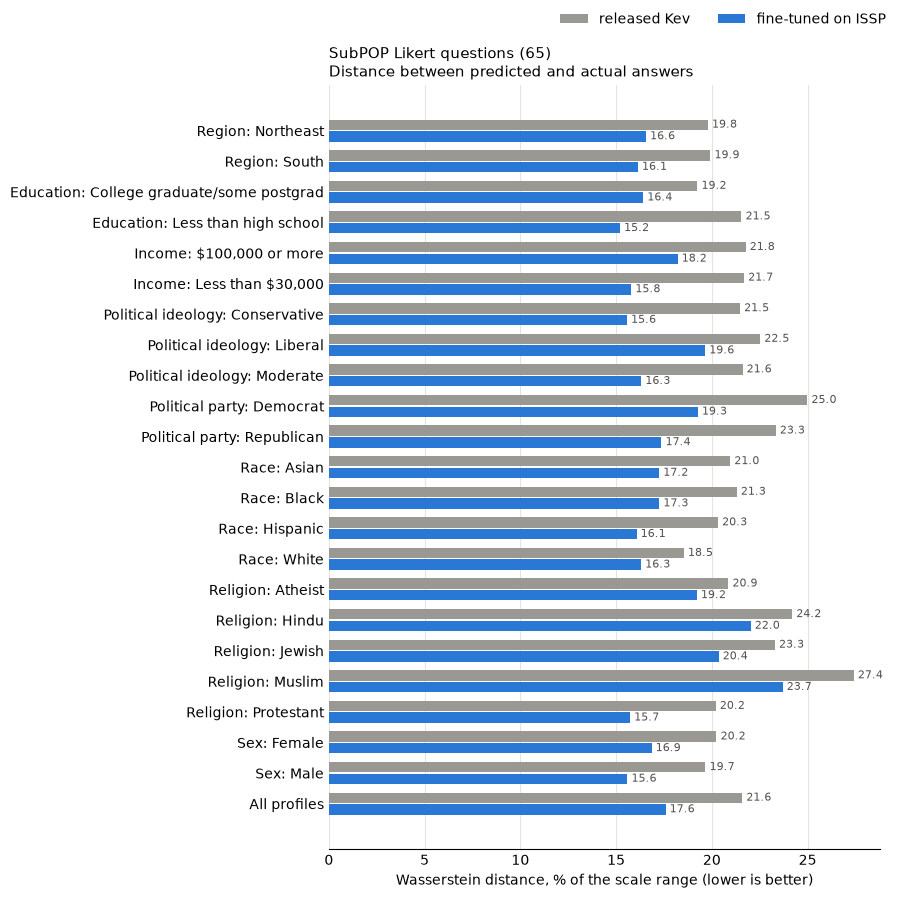

In [38]:
import matplotlib.pyplot as plt

COLORS = {"released Kev": "#9a9893", "fine-tuned on ISSP": "#2a78d6"}   # baseline gray, our model blue
BAR = 0.38                                                               # bar height; two bars per profile

values = wasserstein_table["% of range"]
labels = ["All profiles" if attribute == "all" else f"{ATTRIBUTE[attribute]}: {group}" for attribute, group in values.index]
y = np.arange(len(labels))[::-1]                                         # first profile at the top

fig, ax = plt.subplots(figsize=(9, 9))
for offset, (name, color) in zip([BAR / 2, -BAR / 2], COLORS.items()):
    bars = ax.barh(y + offset, values[name], height=BAR - 0.04, color=color, label=name)
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8, color="#52514e")
ax.set_yticks(y, labels)
ax.set_xlabel("Wasserstein distance, % of the scale range (lower is better)")
ax.set_title(f"SubPOP Likert questions ({len(likert_questions)})\nDistance between predicted and actual answers",
             loc="left", fontsize=11)
fig.legend(loc="upper right", ncol=2, frameon=False)                    # above the bars
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", color="#e6e4df", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()